# Who were the best midfielders and forwards in the 2026 NWSL season, and why?

**Question.** Which NWSL midfielders and forwards created the most value in the 2026 regular season, and which on-ball actions (passing, receiving, dribbling, shooting, defending, fouling) explain why they stand out?

**Data.** [American Soccer Analysis](https://app.americansocceranalysis.com/) (ASA) public API for the 2026 NWSL regular season: all 240 games and 16 teams. ASA builds its models from full event data. This project uses three of them:
- **xGoals:** shots, goals, expected goals (xG), key passes, assists and expected assists (xA)
- **xPass:** passing volume, completion %, and completion *over expected* (a model of how hard each pass was)
- **Goals added (g+):** the change in a team's chance of scoring *and* conceding caused by every on-ball action, split into six action types: **passing, receiving, dribbling, shooting, interrupting** (tackles, interceptions, blocks, clearances) and **fouling** (fouls committed and drawn). ASA also counts each player's actions of each type.

**Approach.**
1. Build per-90 rates for every midfielder and forward with at least 900 regular-season minutes.
2. Rank players by **g+ above average per 90**, ASA's all-in-one value metric. Cross-check it with a transparent role-specific composite score.
3. Explain the rankings: which action types make up each top player's value, which ones account for the *differences* between players, and which actions separate the top 10 from the rest.

*Key terms:* **npxG** is non-penalty expected goals, and **xA** is the xG of the shots a player's passes set up. **g+ above average** compares a player's value to an average player at the same position given the same number of actions, so 0 means average. All rates are **per 90 minutes**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import asa_metrics as A
import plotting as P

SEASON = '2026'
P.set_style()
FIG_DIR = ROOT / 'figures' / SEASON
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 40)
pd.set_option('display.precision', 2)

## 1. Load the data
`src/load_asa.py` downloads and caches the ASA tables and joins them into one row per player. Run it once before this notebook (`python src/load_asa.py {SEASON}`).

In [2]:
path = ROOT / 'data' / 'processed' / f'asa_players_{SEASON}.parquet'
if not path.exists():
    raise FileNotFoundError(f'Run `python src/load_asa.py {SEASON}` first.')
raw = pd.read_parquet(path)
print(f'{len(raw)} players appeared in the {SEASON} regular season')
print(f"{raw['goals'].sum():.0f} goals ({raw['pen_goals'].sum():.0f} penalties), {raw['xgoals'].sum():.1f} xG")

players = A.per90_table(raw, min_minutes=900)
fwd = players[players['position_group'] == 'Forward'].copy()
mid = players[players['position_group'] == 'Midfielder'].copy()
print(f'Qualified (900+ min): {len(fwd)} forwards, {len(mid)} midfielders')
players.groupby('position_group')[['minutes', 'npxg_plus_xa_p90', 'ga_total_p90', 'passes_p90', 'pass_over_exp',
                                    'n_interrupting_p90', 'n_fouling_p90']].mean()

404 players appeared in the 2026 regular season
659 goals (54 penalties), 718.9 xG
Qualified (900+ min): 66 forwards, 61 midfielders


,minutes,npxg_plus_xa_p90,ga_total_p90,passes_p90,pass_over_exp,n_interrupting_p90,n_fouling_p90
position_group,,,,,,,
Defender,1998.04,9.22e-02,-0.01,44.37,1.48,10.30,1.37
Forward,1784.79,3.99e-01,0.02,22.34,-1.71,5.40,2.22
Goalkeeper,2308.11,4.19e-03,0.00,33.22,-0.11,0.00,0.00
Midfielder,2001.08,1.85e-01,-0.02,35.35,1.44,8.16,1.80


## 2. Forwards
### 2.1 Who creates the most chances, for themselves and others?
`npxG + xA per 90` measures the quality of chances a forward takes and sets up, independent of finishing luck. The dot shows actual non-penalty goals + assists per 90.

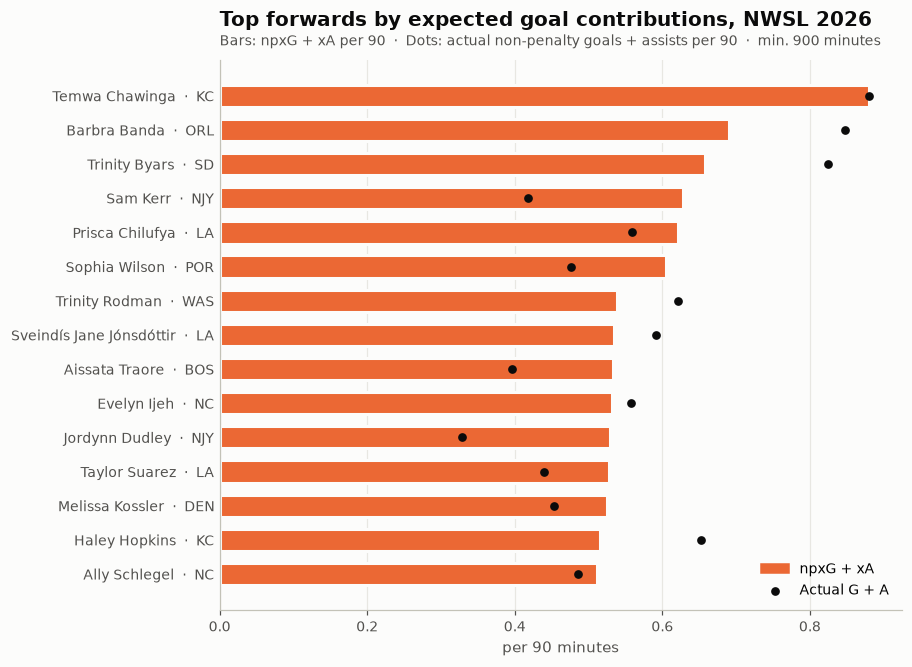

In [3]:
fig, ax = plt.subplots(figsize=(8, 6.5))
P.leaderboard(ax, fwd, 'npxg_plus_xa_p90', P.FWD, n=15, actual='g_plus_a_p90')
ax.set_xlabel('per 90 minutes')
ax.set_title(f'Top forwards by expected goal contributions, NWSL {SEASON}')
P.subtitle(ax, 'Bars: npxG + xA per 90  ·  Dots: actual non-penalty goals + assists per 90  ·  min. 900 minutes')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=P.FWD), ax.collections[-1]],
          labels=['npxG + xA', 'Actual G + A'], loc='lower right')
fig.savefig(FIG_DIR / 'forwards_leaderboard.png')
plt.show()

### 2.2 Volume or quality?
npxG per 90 = shots per 90 × xG per shot. Some forwards shoot often; others wait for better chances.

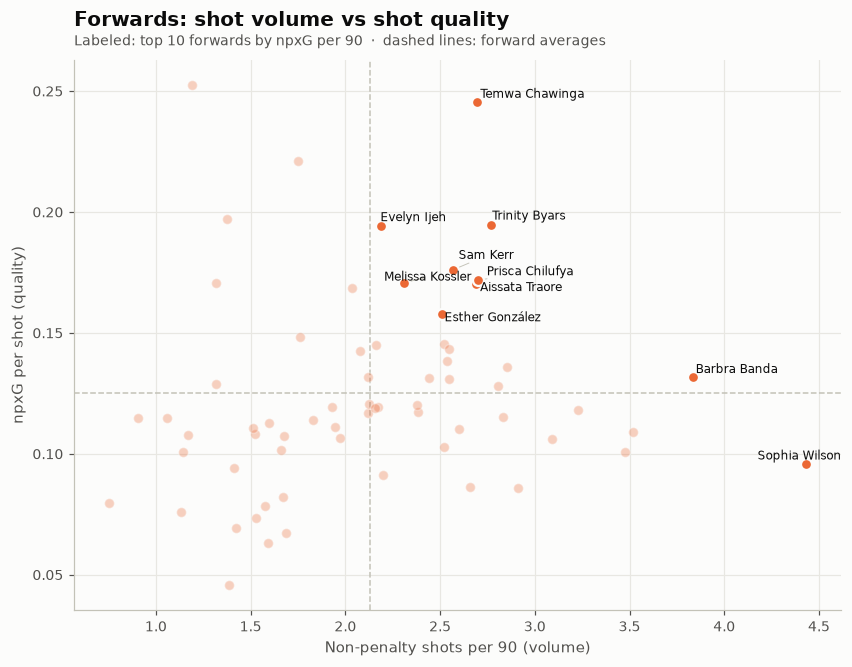

In [4]:
f = fwd.dropna(subset=['xg_per_shot'])
label = f['player_id'].isin(f.nlargest(10, 'np_xg_p90')['player_id'])
fig, ax = plt.subplots(figsize=(9, 6.5))
P.mean_lines(ax, f, 'shots_p90', 'xg_per_shot')
P.labeled_scatter(ax, f, 'shots_p90', 'xg_per_shot', label, P.FWD)
ax.set_xlabel('Non-penalty shots per 90 (volume)')
ax.set_ylabel('npxG per shot (quality)')
ax.set_title('Forwards: shot volume vs shot quality')
P.subtitle(ax, 'Labeled: top 10 forwards by npxG per 90  ·  dashed lines: forward averages')
fig.savefig(FIG_DIR / 'forwards_volume_quality.png')
plt.show()

### 2.3 Finishing: who scored more than their chances suggested?
Points above the diagonal scored more non-penalty goals than their xG predicted. Over a single season this is a mix of finishing skill and luck.

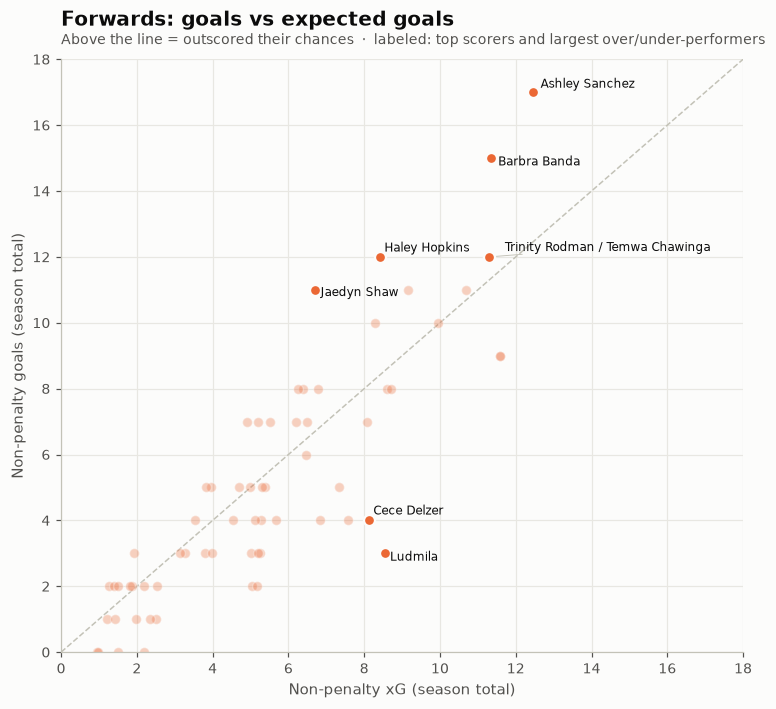

,display_name,team_short,np_shots,np_goals,np_xg,goals_minus_xg
185,Ashley Sanchez,NC,114,17,12.44,4.56
32,Jaedyn Shaw,NJY,56,11,6.69,4.31
79,Barbra Banda,ORL,86,15,11.34,3.66
197,Haley Hopkins,KC,50,12,8.42,3.58
100,Melanie Barcenas,SD,57,7,4.90,2.10
156,Trinity Byars,SD,47,11,9.16,1.84
169,Cloe Lacasse,UTA,47,7,5.19,1.81
61,Natasha Flint,DEN,61,8,6.26,1.74


In [5]:
fig, ax = plt.subplots(figsize=(8, 7))
lim = max(fwd['np_xg'].max(), fwd['np_goals'].max()) + 1
ax.plot([0, lim], [0, lim], color=P.MUTED, lw=1, ls='--', zorder=1)
label = (fwd['goals_minus_xg'].abs().rank(ascending=False) <= 5) | (fwd['np_goals'].rank(ascending=False) <= 5)
P.labeled_scatter(ax, fwd, 'np_xg', 'np_goals', label, P.FWD)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('Non-penalty xG (season total)')
ax.set_ylabel('Non-penalty goals (season total)')
ax.set_title('Forwards: goals vs expected goals')
P.subtitle(ax, 'Above the line = outscored their chances  ·  labeled: top scorers and largest over/under-performers')
fig.savefig(FIG_DIR / 'forwards_finishing.png')
plt.show()

fwd[['display_name', 'team_short', 'np_shots', 'np_goals', 'np_xg', 'goals_minus_xg']] \
    .sort_values('goals_minus_xg', ascending=False).head(8)

## 3. Midfielders
### 3.1 Archetypes: value from passing vs value from winning the ball
The x-axis is g+ from **passing** per 90 (value added by passes compared with an average player). The y-axis is g+ from **interrupting** per 90 (value from tackles, interceptions, blocks and clearances).

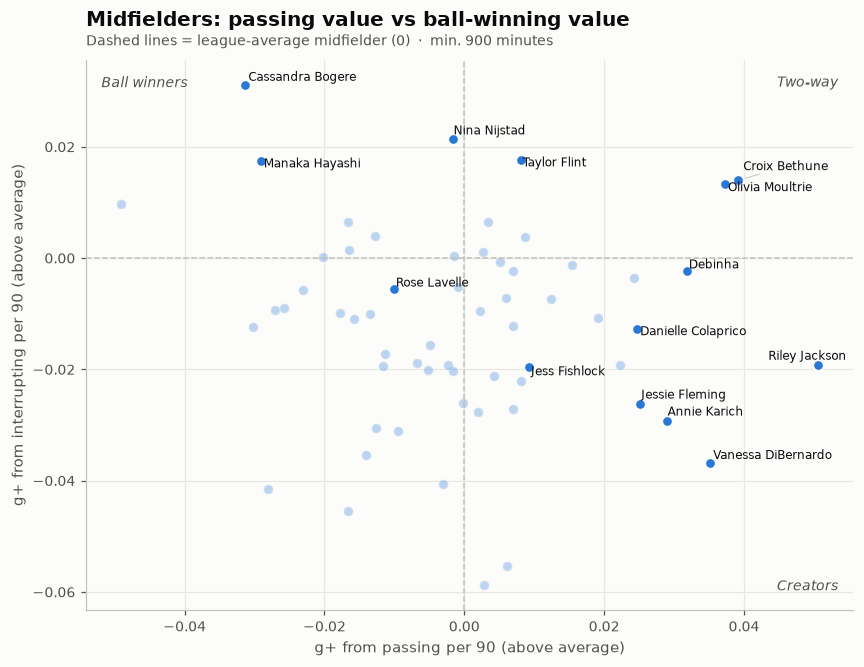

In [6]:
label = mid['player_id'].isin(pd.concat([mid.nlargest(8, 'ga_passing_p90')['player_id'],
                                         mid.nlargest(5, 'ga_interrupting_p90')['player_id'],
                                         mid.nlargest(5, 'ga_total_p90')['player_id']]))
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.axvline(0, color=P.MUTED, lw=1, ls='--'); ax.axhline(0, color=P.MUTED, lw=1, ls='--')
P.labeled_scatter(ax, mid, 'ga_passing_p90', 'ga_interrupting_p90', label, P.MID)
ax.set_xlabel('g+ from passing per 90 (above average)')
ax.set_ylabel('g+ from interrupting per 90 (above average)')
ax.set_title('Midfielders: passing value vs ball-winning value')
P.subtitle(ax, 'Dashed lines = league-average midfielder (0)  ·  min. 900 minutes')
for txt, xy in [('Creators', (0.98, 0.03)), ('Two-way', (0.98, 0.97)), ('Ball winners', (0.02, 0.97))]:
    ax.text(*xy, txt, transform=ax.transAxes, color=P.TEXT_2, fontsize=9, style='italic',
            ha='right' if xy[0] > 0.5 else 'left', va='top' if xy[1] > 0.5 else 'bottom')
fig.savefig(FIG_DIR / 'midfielders_archetypes.png')
plt.show()

### 3.2 Safe or direct? Passing skill vs passing ambition
**Completion over expected** (per 100 passes) credits players for completing passes that are harder than average. **Average vertical distance** shows how far forward their passes travel. The best passers are both accurate *and* direct (top right).

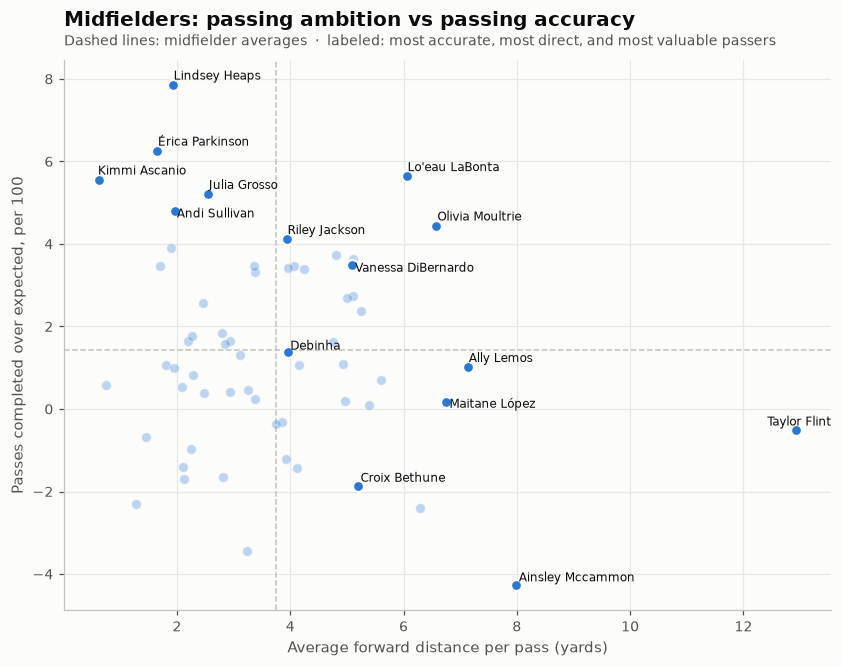

In [7]:
label = mid['player_id'].isin(pd.concat([mid.nlargest(6, 'pass_over_exp')['player_id'],
                                         mid.nlargest(5, 'vertical_yds')['player_id'],
                                         mid.nlargest(5, 'ga_passing_p90')['player_id']]))
fig, ax = plt.subplots(figsize=(9, 6.5))
P.mean_lines(ax, mid, 'vertical_yds', 'pass_over_exp')
P.labeled_scatter(ax, mid, 'vertical_yds', 'pass_over_exp', label, P.MID)
ax.set_xlabel('Average forward distance per pass (yards)')
ax.set_ylabel('Passes completed over expected, per 100')
ax.set_title('Midfielders: passing ambition vs passing accuracy')
P.subtitle(ax, 'Dashed lines: midfielder averages  ·  labeled: most accurate, most direct, and most valuable passers')
fig.savefig(FIG_DIR / 'midfielders_passing.png')
plt.show()

## 4. Ranking the best: goals added (g+)
g+ adds up the value of everything a player does on the ball, positive and negative. The chart breaks each player's total into the six action types. Bars right of zero are above-average value; bars left of zero are below average.

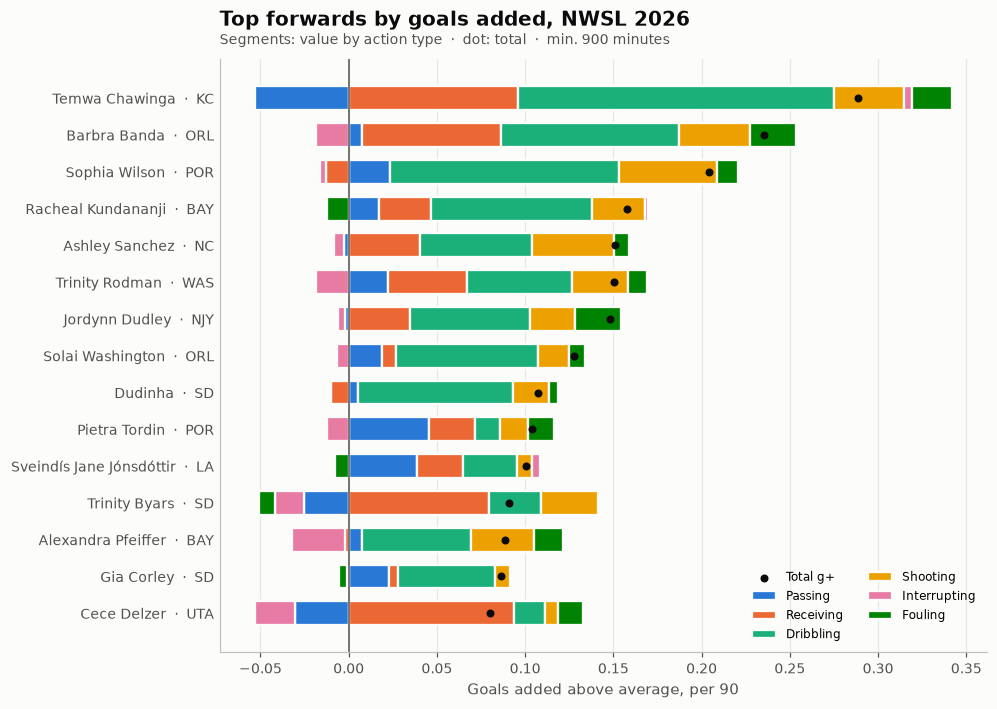

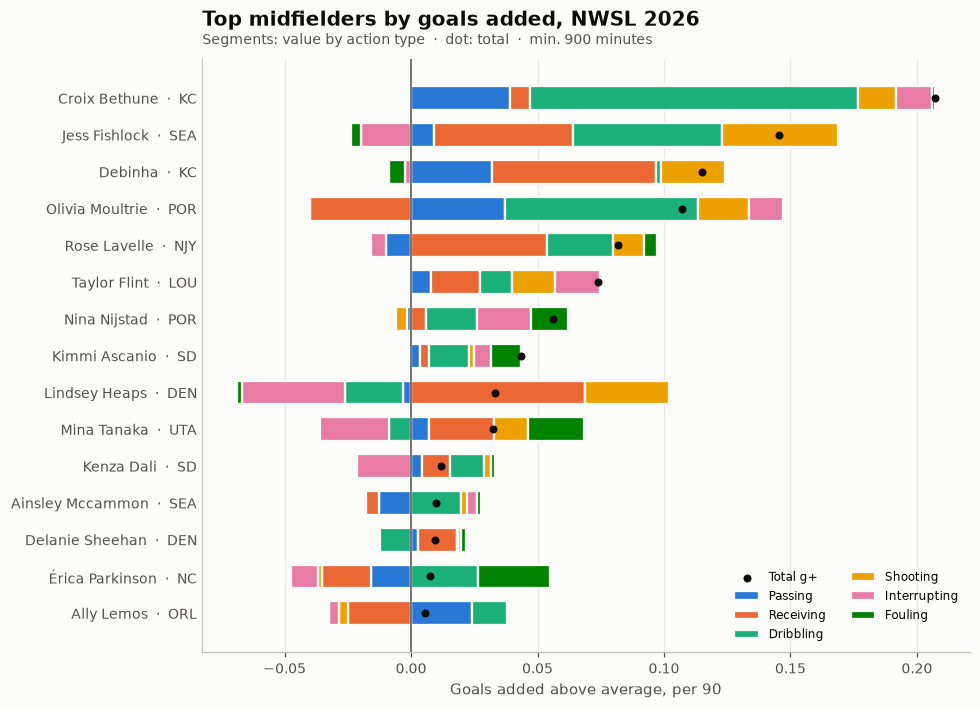

In [8]:
def ga_breakdown(df, color_title, fname, n=15):
    top = df.nlargest(n, 'ga_total_p90').iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 7))
    y = np.arange(len(top))
    pos_left = np.zeros(len(top)); neg_left = np.zeros(len(top))
    for action, color in zip(A.GA_ACTIONS, P.ACTION_COLORS):
        v = top[f'ga_{action}_p90'].to_numpy()
        left = np.where(v >= 0, pos_left, neg_left)
        ax.barh(y, v, left=left, color=color, height=0.65, edgecolor=P.SURFACE, linewidth=1.5,
                label=A.GA_LABELS[action])
        pos_left += np.where(v >= 0, v, 0); neg_left += np.where(v < 0, v, 0)
    ax.scatter(top['ga_total_p90'], y, color=P.TEXT, s=18, zorder=3, label='Total g+')
    ax.axvline(0, color=P.TEXT_2, lw=1)
    ax.set_yticks(y, [f'{r.display_name}  ·  {r.team_short}' for r in top.itertuples()])
    ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
    ax.set_xlabel('Goals added above average, per 90')
    ax.set_title(color_title)
    P.subtitle(ax, 'Segments: value by action type  ·  dot: total  ·  min. 900 minutes')
    ax.legend(loc='lower right', ncol=2, fontsize=8)
    fig.savefig(FIG_DIR / fname)
    plt.show()


ga_breakdown(fwd, f'Top forwards by goals added, NWSL {SEASON}', 'forwards_goals_added.png')
ga_breakdown(mid, f'Top midfielders by goals added, NWSL {SEASON}', 'midfielders_goals_added.png')

### 4.1 Cross-check: a transparent composite score
g+ is one model's view, so I also build a role-specific composite from within-position percentiles. The weights are a judgment call and are written out below. A player who ranks highly on **both** is a safe pick for "best".

| Role | Category (weight) | Metrics |
|---|---|---|
| Forward | Shooting (40%) | npxG, shots, non-penalty goals |
| | Creation (30%) | xA, key passes, assists |
| | Ball carrying (20%) | g+ dribbling, g+ receiving, dribbles |
| | Defending (10%) | g+ interrupting, interrupting actions |
| Midfielder | Passing (35%) | g+ passing, completion over expected, forward distance per pass |
| | Creation (25%) | xA, key passes, assists |
| | Defending (25%) | g+ interrupting, interrupting actions |
| | Attacking (15%) | npxG, non-penalty G + A |

In [9]:
ROLE_CATEGORIES = {
    'Forward': {
        'Shooting':  (0.40, ['np_xg_p90', 'shots_p90', 'np_goals_p90']),
        'Creation':  (0.30, ['xa_p90', 'key_passes_p90', 'assists_p90']),
        'Carrying':  (0.20, ['ga_dribbling_p90', 'ga_receiving_p90', 'n_dribbling_p90']),
        'Defending': (0.10, ['ga_interrupting_p90', 'n_interrupting_p90']),
    },
    'Midfielder': {
        'Passing':   (0.35, ['ga_passing_p90', 'pass_over_exp', 'vertical_yds']),
        'Creation':  (0.25, ['xa_p90', 'key_passes_p90', 'assists_p90']),
        'Defending': (0.25, ['ga_interrupting_p90', 'n_interrupting_p90']),
        'Attacking': (0.15, ['np_xg_p90', 'g_plus_a_p90']),
    },
}
fwd = A.composite(fwd, ROLE_CATEGORIES['Forward'])
mid = A.composite(mid, ROLE_CATEGORIES['Midfielder'])
for df in (fwd, mid):
    df['ga_rank'] = df['ga_total_p90'].rank(ascending=False, method='min').astype(int)
    df['avg_rank'] = (df['ga_rank'] + df['composite_rank']) / 2

show = ['display_name', 'team_short', 'position', 'minutes', 'ga_total_p90', 'ga_rank', 'score', 'composite_rank']
print('TOP 10 FORWARDS (sorted by average of the two ranks)')
display(fwd.sort_values('avg_rank')[show + ['np_goals', 'primary_assists', 'np_xg', 'xassists']].head(10).round(2))
print('TOP 10 MIDFIELDERS (sorted by average of the two ranks)')
display(mid.sort_values('avg_rank')[show + ['np_goals', 'primary_assists', 'xassists', 'pass_over_exp']].head(10).round(2))
print(f"Rank agreement (Spearman): forwards {fwd['ga_rank'].corr(fwd['composite_rank'], method='spearman'):.2f}, "
      f"midfielders {mid['ga_rank'].corr(mid['composite_rank'], method='spearman'):.2f}")

TOP 10 FORWARDS (sorted by average of the two ranks)


,display_name,team_short,position,minutes,ga_total_p90,ga_rank,score,composite_rank,np_goals,primary_assists,np_xg,xassists
177,Temwa Chawinga,KC,Winger,1535,0.29,1,85.81,1,12,3,11.30,3.71
79,Barbra Banda,ORL,Striker,2019,0.24,2,81.92,2,15,4,11.34,4.14
60,Sophia Wilson,POR,Striker,2456,0.20,3,77.05,5,9,4,11.58,4.92
105,Trinity Rodman,WAS,Winger,2900,0.15,6,79.17,3,12,8,11.29,6.06
14,Racheal Kundananji,BAY,Winger,1315,0.16,4,71.41,9,3,3,5.25,1.63
99,Dudinha,SD,Winger,1247,0.11,9,78.43,4,5,4,3.96,2.79
155,Jordynn Dudley,NJY,Winger,1915,0.15,7,71.89,8,4,3,6.83,4.44
185,Ashley Sanchez,NC,Winger,2917,0.15,5,71.06,10,17,3,12.44,2.78
68,Sveindís Jane Jónsdóttir,LA,Striker,2129,0.10,11,74.55,6,10,4,8.30,4.34
156,Trinity Byars,SD,Striker,1527,0.09,12,72.22,7,11,3,9.16,2.00


TOP 10 MIDFIELDERS (sorted by average of the two ranks)


,display_name,team_short,position,minutes,ga_total_p90,ga_rank,score,composite_rank,np_goals,primary_assists,xassists,pass_over_exp
153,Croix Bethune,KC,Attacking mid,2227,0.21,1,77.88,2,4,10,6.57,-1.86
50,Olivia Moultrie,POR,Attacking mid,1460,0.11,4,86.11,1,4,5,2.45,4.45
22,Debinha,KC,Attacking mid,1737,0.12,3,69.55,6,7,1,3.70,1.37
170,Nina Nijstad,POR,Defensive mid,1198,0.06,7,71.09,4,1,1,1.45,3.64
241,Kimmi Ascanio,SD,Defensive mid,2318,0.04,8,65.94,8,1,3,2.22,5.56
23,Jess Fishlock,SEA,Attacking mid,914,0.15,2,59.81,16,4,1,0.78,3.39
26,Taylor Flint,LOU,Defensive mid,1868,0.07,6,60.42,15,2,0,0.50,-0.52
186,Ally Lemos,ORL,Defensive mid,2546,0.01,15,68.16,7,1,3,3.88,1.02
193,Rose Lavelle,NJY,Attacking mid,2123,0.08,5,58.43,19,4,2,4.28,1.85
162,Riley Jackson,NC,Central mid,2371,0.00,17,65.19,9,0,2,4.38,4.12


Rank agreement (Spearman): forwards 0.92, midfielders 0.74


### 4.2 Player profiles
Each top-three player (by average rank) as a percentile against others in their position group (100 = best).

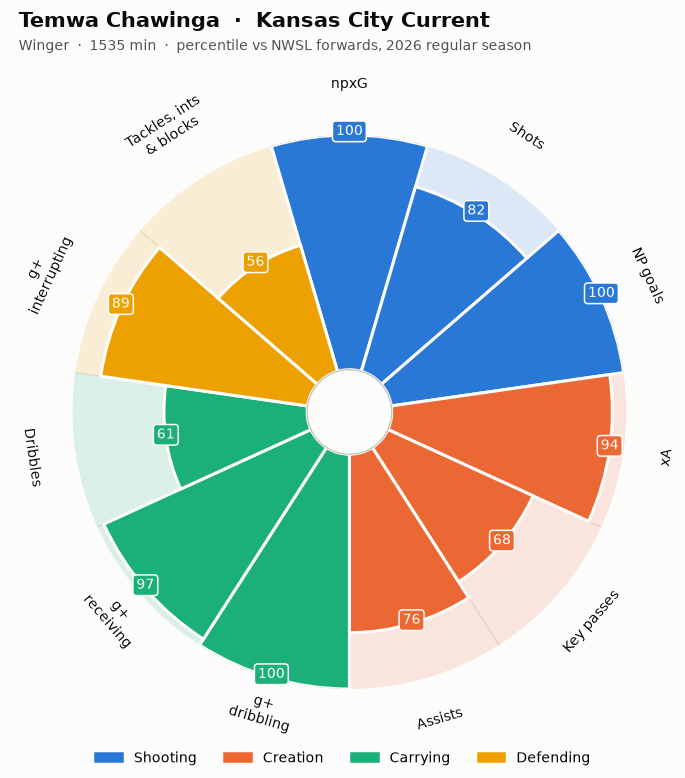

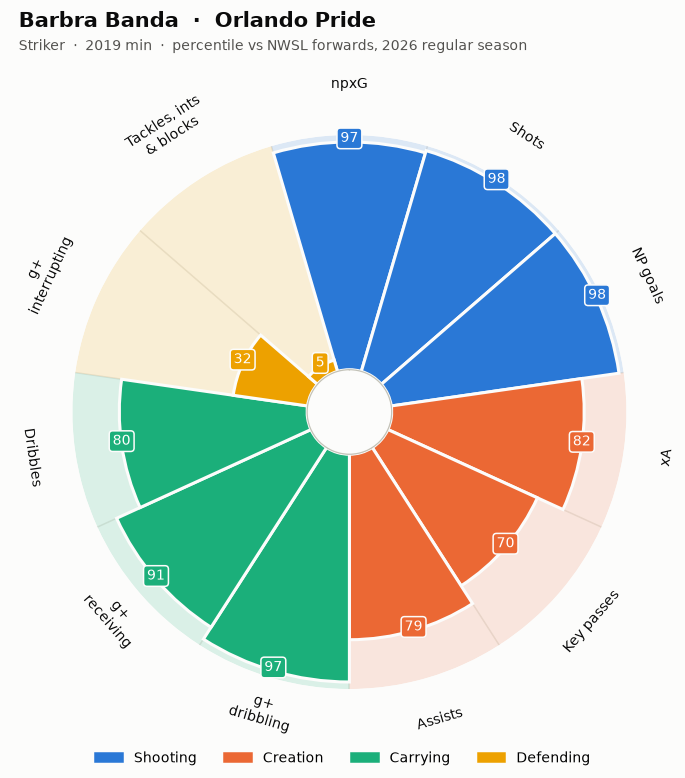

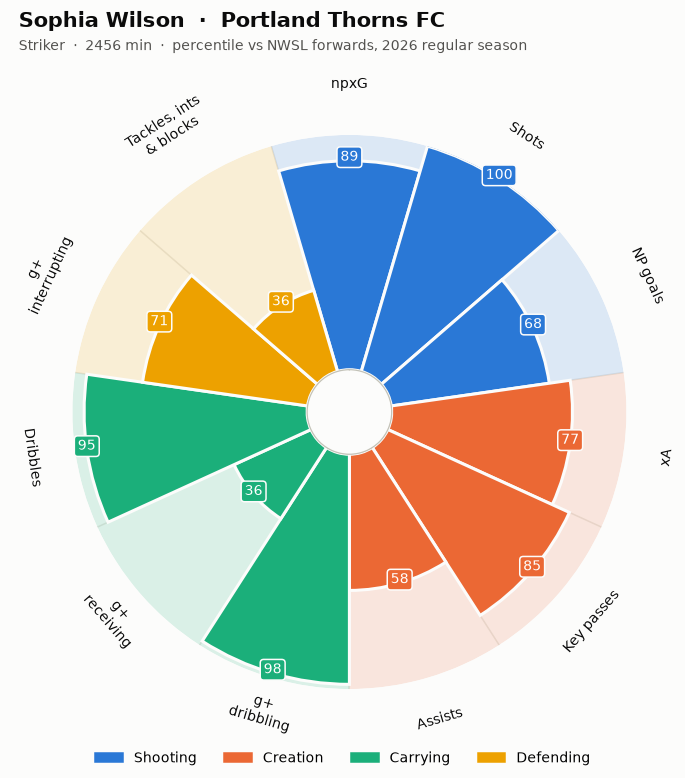

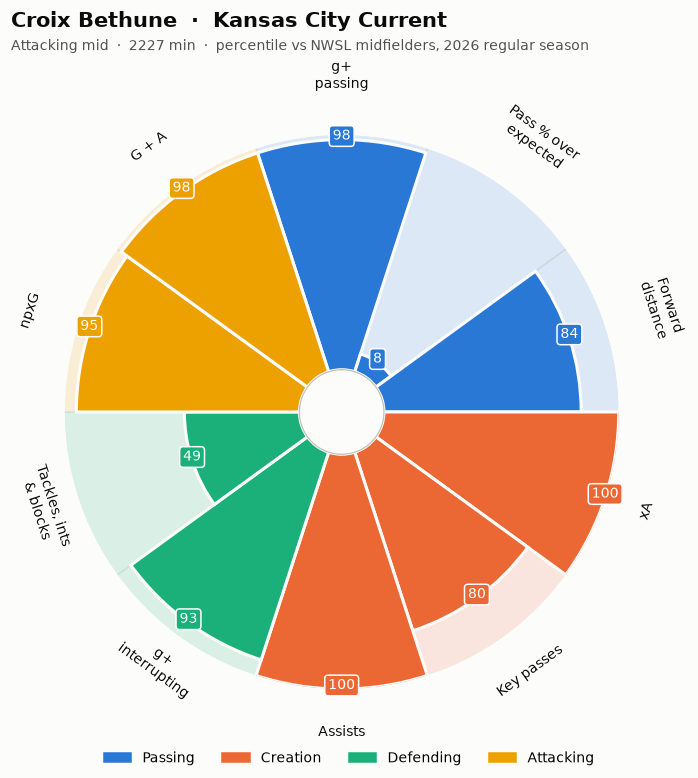

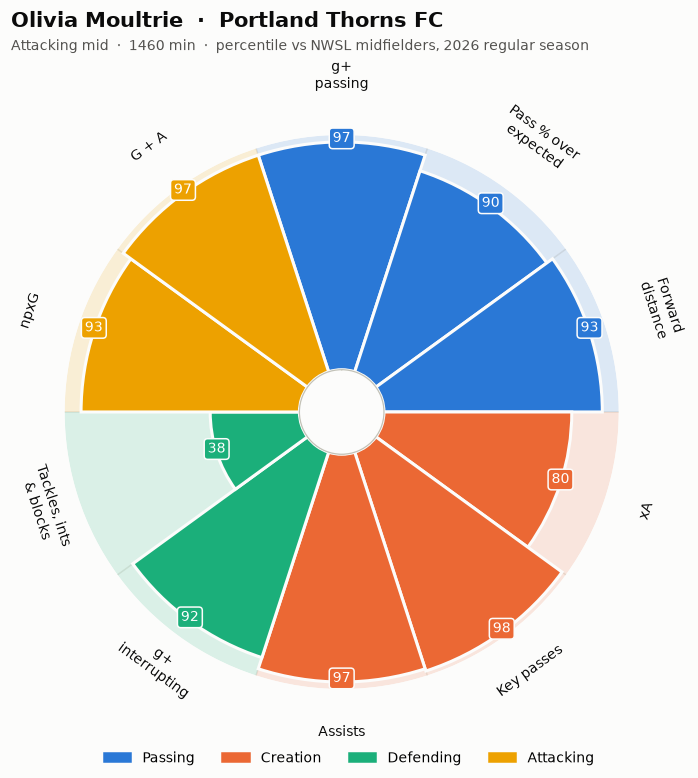

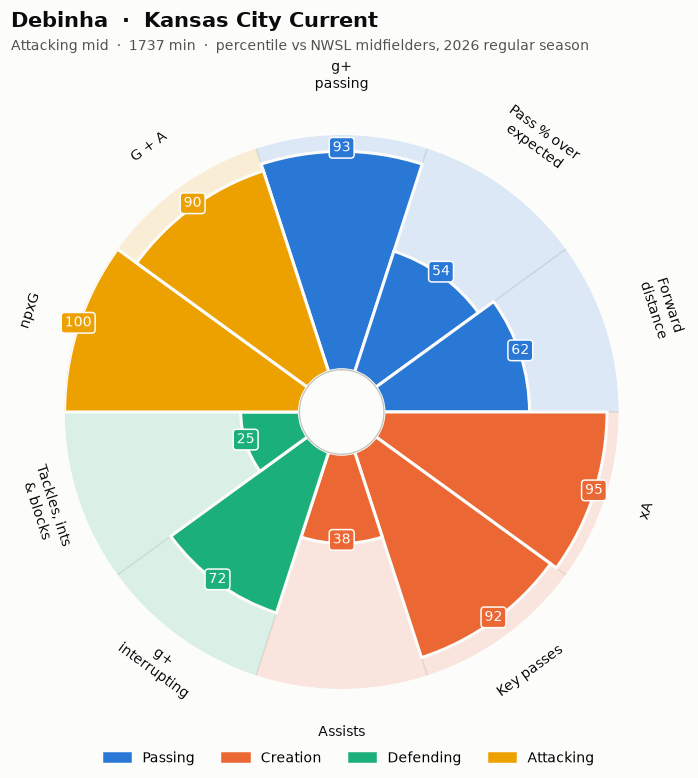

In [10]:
PIZZA_LABELS = {
    'np_xg_p90': 'npxG', 'shots_p90': 'Shots', 'np_goals_p90': 'NP goals', 'xa_p90': 'xA',
    'key_passes_p90': 'Key passes', 'assists_p90': 'Assists', 'ga_dribbling_p90': 'g+\ndribbling',
    'ga_receiving_p90': 'g+\nreceiving', 'n_dribbling_p90': 'Dribbles', 'ga_interrupting_p90': 'g+\ninterrupting',
    'n_interrupting_p90': 'Tackles, ints\n& blocks', 'ga_passing_p90': 'g+\npassing',
    'pass_over_exp': 'Pass % over\nexpected', 'vertical_yds': 'Forward\ndistance', 'g_plus_a_p90': 'G + A',
}
for group, df in [('Forward', fwd), ('Midfielder', mid)]:
    for i, (_, row) in enumerate(df.sort_values('avg_rank').head(3).iterrows(), start=1):
        P.pizza(df, row, ROLE_CATEGORIES[group], PIZZA_LABELS,
                title=f"{row['display_name']}  ·  {row['team_name']}",
                subtitle_text=f"{row['position']}  ·  {row['minutes']:.0f} min  ·  "
                              f"percentile vs NWSL {group.lower()}s, {SEASON} regular season",
                path=FIG_DIR / f"pizza_{'fwd' if group == 'Forward' else 'mid'}_{i}.png")
        plt.show()

## 5. Why: what makes the best players the best?
### 5.1 Which actions drive the differences between players?
Total g+ is the sum of its six action types, so the **variance** in total g+ splits exactly into each action type's share: cov(action, total) / var(total). This answers: *when one player is more valuable than another, which kind of action is usually the reason?*

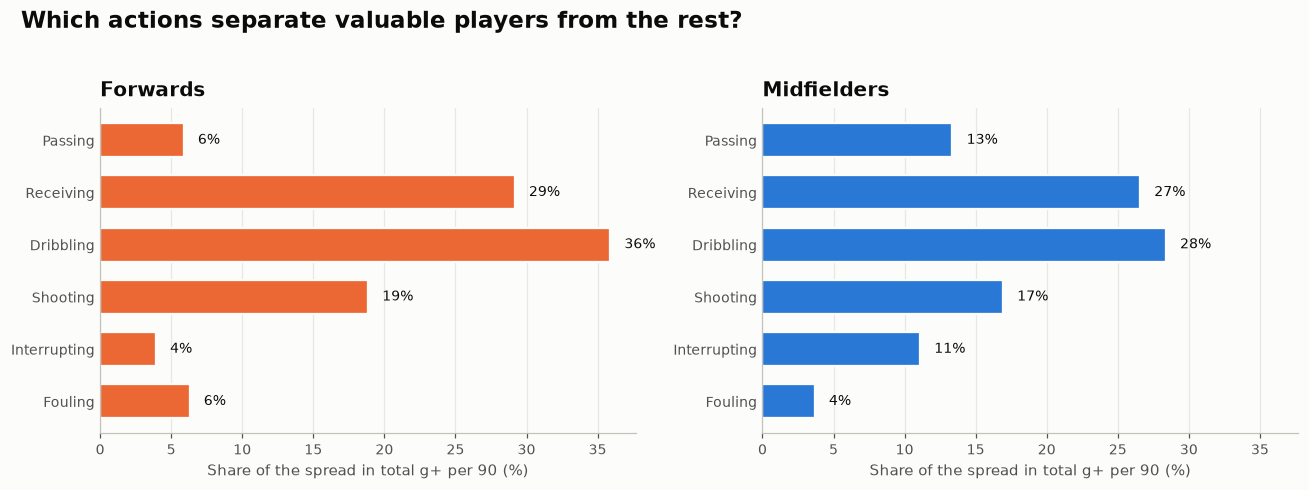

,Forwards,Midfielders
Passing,5.9,13.4
Receiving,29.2,26.6
Dribbling,35.9,28.4
Shooting,18.8,16.9
Interrupting,3.9,11.1
Fouling,6.3,3.7


In [11]:
parts = [f'ga_{a}_p90' for a in A.GA_ACTIONS]
shares = pd.DataFrame({
    'Forwards': A.variance_share(fwd, parts, 'ga_total_p90'),
    'Midfielders': A.variance_share(mid, parts, 'ga_total_p90'),
})
shares.index = [A.GA_LABELS[a] for a in A.GA_ACTIONS]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, col, color in [(axes[0], 'Forwards', P.FWD), (axes[1], 'Midfielders', P.MID)]:
    s = shares[col].iloc[::-1]
    ax.barh(np.arange(len(s)), s.values * 100, color=[color if v > 0 else P.MUTED for v in s.values],
            height=0.65, edgecolor=P.SURFACE, linewidth=1.5)
    ax.set_yticks(np.arange(len(s)), s.index)
    ax.axvline(0, color=P.TEXT_2, lw=1)
    ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
    for yi, v in enumerate(s.values):
        ax.text(max(v, 0) * 100 + 1, yi, f'{v:.0%}', va='center', ha='left', fontsize=9, color=P.TEXT)
    ax.set_xlabel('Share of the spread in total g+ per 90 (%)')
    ax.set_title(col, pad=8)
fig.suptitle('Which actions separate valuable players from the rest?', x=0.02, ha='left',
             fontsize=15, fontweight='bold', color=P.TEXT)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIG_DIR / 'why_variance_share.png')
plt.show()
(shares * 100).round(1)

### 5.2 What separates the top 10 from the rest?
For every metric: (top-10 average − rest average) / pooled standard deviation, with the top 10 chosen by g+ per 90. A value of 1.0 means the top 10 are a full standard deviation higher. Grey bars are things the best players do *less* of.

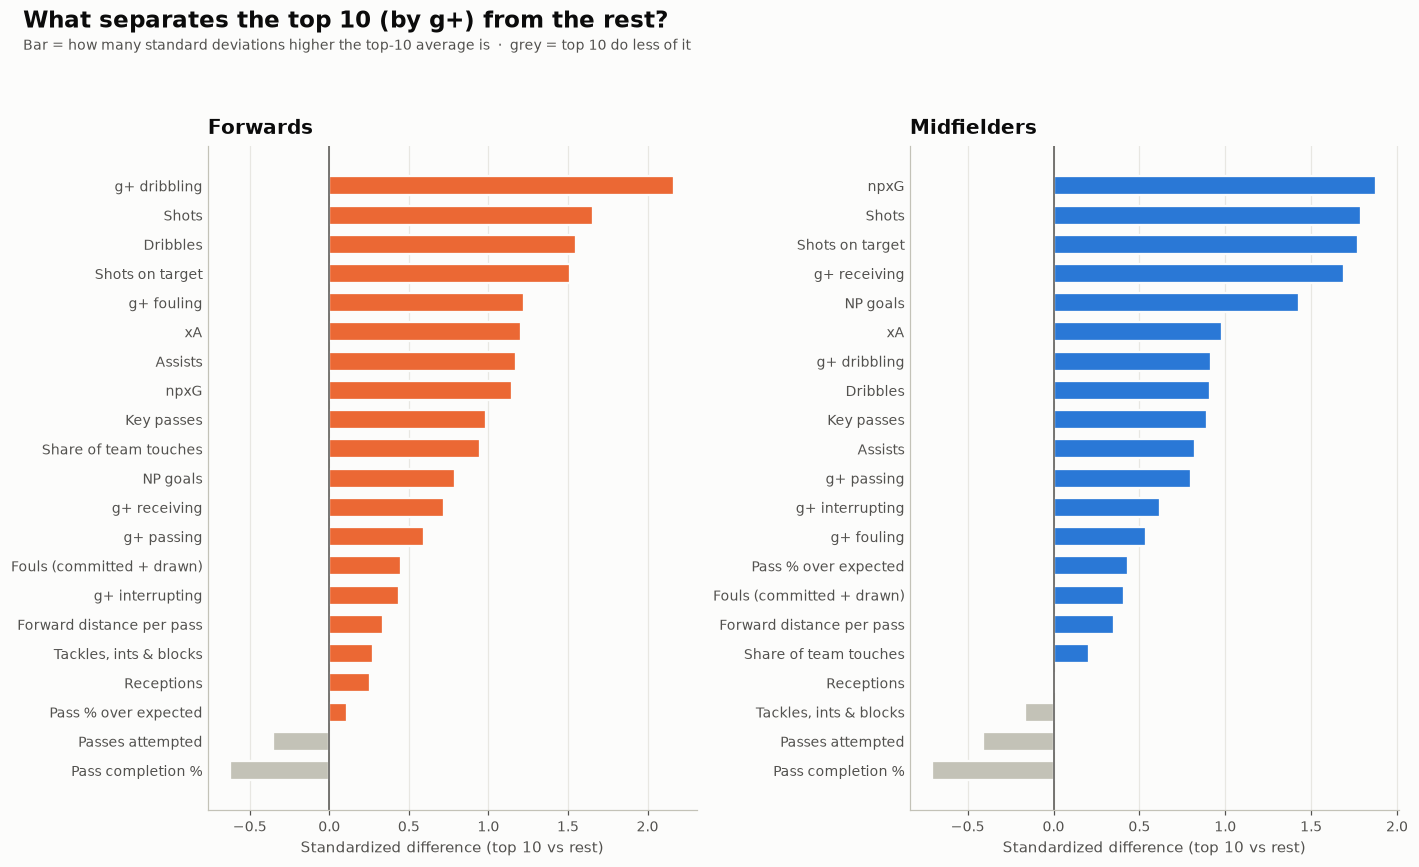

Forwards                    Midfielders         \
                             top10   rest effect_size       top10   rest   
metric                                                                     
g+ dribbling                  0.09   0.01        2.17        0.03  -0.00   
Shots                         3.06   1.96        1.66        1.91   0.94   
Dribbles                     17.42  12.56        1.55       13.20  10.02   
Shots on target               1.28   0.76        1.51        0.80   0.29   
g+ fouling                    0.01  -0.00        1.22        0.00  -0.00   
xA                            0.18   0.12        1.21        0.14   0.08   
Assists                       0.19   0.11        1.17        0.15   0.07   
npxG                          0.39   0.25        1.15        0.23   0.07   
Key passes                    1.37   1.04        0.98        1.31   0.89   
Share of team touches         5.94   4.83        0.95        7.57   7.12   
NP goals                      0.37   0.23        0.79        0.23   0.06   
g+ receiving                  0.03   0.00        0.72        0.03  -0.02   
g+ passing                    0.01  -0.01        0.59        0.01  -0.00   
Fouls (committed + drawn)     2.59   2.15        0.45        2.09   1.75   
g+ interrupting              -0.01  -0.01        0.44       -0.00  -0.01   
Forward distance per pass     1.63   0.96        0.34        4.55   3.59   
Tackles, ints & blocks        5.77   5.33        0.28        7.72   8.25   
Receptions                   22.60  21.51        0.26       27.71  27.61   
Pass % over expected         -1.47  -1.75        0.11        2.43   1.24   
Passes attempted             20.84  22.61       -0.36       32.32  35.95   
Pass completion %            65.80  68.82       -0.62       73.91  77.97   

                                       
                          effect_size  
metric                                 
g+ dribbling                     0.92  
Shots                            1.79  
Dribbles                         0.91  
Shots on target                  1.77  
g+ fouling                       0.54  
xA                               0.98  
Assists                          0.82  
npxG                             1.88  
Key passes                       0.89  
Share of team touches            0.21  
NP goals                         1.43  
g+ receiving                     1.69  
g+ passing                       0.80  
Fouls (committed + drawn)        0.41  
g+ interrupting                  0.62  
Forward distance per pass        0.35  
Tackles, ints & blocks          -0.16  
Receptions                       0.01  
Pass % over expected             0.43  
Passes attempted                -0.41  
Pass completion %               -0.71

In [12]:
WHY_METRICS = {
    'np_xg_p90': 'npxG', 'shots_p90': 'Shots', 'shots_on_target_p90': 'Shots on target',
    'np_goals_p90': 'NP goals', 'xa_p90': 'xA', 'assists_p90': 'Assists', 'key_passes_p90': 'Key passes',
    'passes_p90': 'Passes attempted', 'pass_pct': 'Pass completion %', 'pass_over_exp': 'Pass % over expected',
    'vertical_yds': 'Forward distance per pass', 'touch_share': 'Share of team touches',
    'n_receiving_p90': 'Receptions', 'n_dribbling_p90': 'Dribbles', 'n_interrupting_p90': 'Tackles, ints & blocks',
    'n_fouling_p90': 'Fouls (committed + drawn)',
    'ga_passing_p90': 'g+ passing', 'ga_receiving_p90': 'g+ receiving', 'ga_dribbling_p90': 'g+ dribbling',
    'ga_interrupting_p90': 'g+ interrupting', 'ga_fouling_p90': 'g+ fouling',
}
sep_fwd = A.separation(fwd, WHY_METRICS)
sep_mid = A.separation(mid, WHY_METRICS)

fig, axes = plt.subplots(1, 2, figsize=(13, 8))
for ax, sep, color, name in [(axes[0], sep_fwd, P.FWD, 'Forwards'), (axes[1], sep_mid, P.MID, 'Midfielders')]:
    y = np.arange(len(sep))
    ax.barh(y, sep['effect_size'], color=[color if v > 0 else P.MUTED for v in sep['effect_size']],
            height=0.65, edgecolor=P.SURFACE, linewidth=1.5)
    ax.axvline(0, color=P.TEXT_2, lw=1)
    ax.set_yticks(y, sep['metric'])
    ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
    ax.set_xlabel('Standardized difference (top 10 vs rest)')
    ax.set_title(name, pad=8)
fig.suptitle('What separates the top 10 (by g+) from the rest?', x=0.02, ha='left', fontsize=15,
             fontweight='bold', color=P.TEXT)
fig.text(0.02, 0.935, 'Bar = how many standard deviations higher the top-10 average is  ·  grey = top 10 do less of it',
         color=P.TEXT_2, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig(FIG_DIR / 'why_separation.png')
plt.show()

pd.concat({'Forwards': sep_fwd.set_index('metric').iloc[::-1].round(2),
           'Midfielders': sep_mid.set_index('metric').iloc[::-1].round(2)}, axis=1)

### 5.3 Which actions go with actual goal contributions?
A check that doesn't depend on g+ or on my weights: Spearman correlation between each action rate and **actual non-penalty goals + assists per 90**, across all qualified midfielders and forwards. Expected metrics built from the same shots and passes (npxG, xA, g+ shooting) are left out.

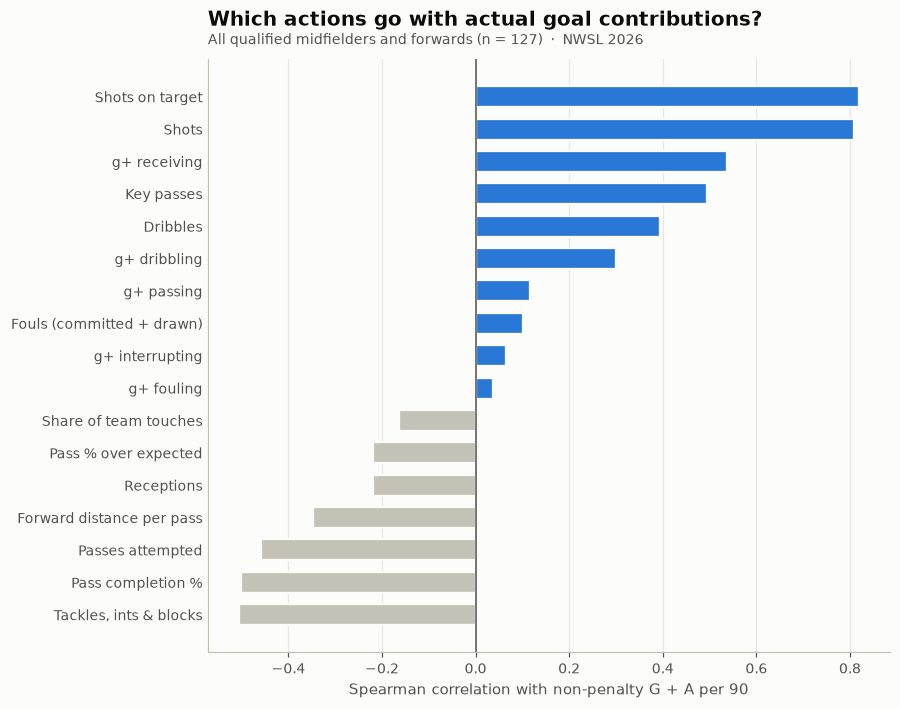

,spearman_r
Shots on target,0.82
Shots,0.81
g+ receiving,0.54
Key passes,0.49
Dribbles,0.39
g+ dribbling,0.30
g+ passing,0.12
Fouls (committed + drawn),0.10
g+ interrupting,0.07
g+ fouling,0.04


In [13]:
attackers = pd.concat([fwd, mid])
candidates = [c for c in WHY_METRICS if c not in {'np_xg_p90', 'np_goals_p90', 'xa_p90', 'assists_p90'}]
corr = (attackers[candidates + ['g_plus_a_p90']].corr(method='spearman')['g_plus_a_p90']
        .drop('g_plus_a_p90').rename(WHY_METRICS).sort_values())

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(corr))
ax.barh(y, corr.values, color=[P.MID if v > 0 else P.MUTED for v in corr.values], height=0.65,
        edgecolor=P.SURFACE, linewidth=1.5)
ax.axvline(0, color=P.TEXT_2, lw=1)
ax.set_yticks(y, corr.index)
ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
ax.set_xlabel('Spearman correlation with non-penalty G + A per 90')
ax.set_title('Which actions go with actual goal contributions?')
P.subtitle(ax, f'All qualified midfielders and forwards (n = {len(attackers)})  ·  NWSL {SEASON}')
fig.savefig(FIG_DIR / 'why_correlation.png')
plt.show()
corr.sort_values(ascending=False).round(2).to_frame('spearman_r')

## 6. Findings
**Best forwards: Temwa Chawinga, Barbra Banda, Sophia Wilson.**
- **Temwa Chawinga** (Kansas City) is #1 by both g+ and the composite. She scored 12 non-penalty goals in only 1,535 minutes and led every qualified player in g+ per 90 (0.29). Most of that value came from dribbling.
- **Barbra Banda** (Orlando) is #2 on both measures, with 15 non-penalty goals from 11.3 npxG. **Sophia Wilson** (Portland) is #3 by g+. **Trinity Rodman** (Washington) is #3 by composite, with 12 goals and 8 assists.
- **Finishing:** Ashley Sanchez (North Carolina) scored the most non-penalty goals (17, from 12.4 npxG). She and Jaedyn Shaw (11 from 6.7) outscored their chances by the most, about +4.5 each.

**Best midfielders: Croix Bethune, Olivia Moultrie, Debinha.**
- **Croix Bethune** (Kansas City) had the highest g+ per 90 of any midfielder (0.21) and 10 assists from 6.6 xA. She is #1 by g+ and #2 by composite.
- **Olivia Moultrie** (Portland) is #1 by composite. She is a two-way attacking midfielder: +4.5 passes completed per 100 over expected, above-average ball winning, and 4 goals plus 5 assists. **Debinha** (Kansas City) is #3 by g+, with 7 non-penalty goals.
- Jess Fishlock is again #2 by g+ per 90, but in only 914 minutes, so she is a strong-but-small-sample case.

**Why: what makes them the best?**
1. **Beating defenders and getting on the ball in dangerous spaces drives the gap.** Dribbling and receiving together account for 65% of the differences in g+ between forwards (dribbling 36%, receiving 29%) and 55% between midfielders (28% and 27%). Passing accounts for only 6% among forwards and 13% among midfielders.
2. **Elite forwards dribble and shoot more.** Top-10 forwards attempt 17.4 dribbles per 90 vs 12.6 for the rest, and take 3.1 shots per 90 vs 2.0. g+ from dribbling is the single biggest separator (+2.2 standard deviations).
3. **Elite midfielders arrive in the box.** The top-10 midfielders take twice as many shots (1.91 vs 0.94 per 90) and produce three times the npxG (0.23 vs 0.07). The most valuable midfielders in 2026 were attacking 8s and 10s.
4. **Harder passes, completed anyway.** Top-10 midfielders have *lower* raw pass completion (73.9% vs 78.0%) but *higher* completion over expected, so they attempt more difficult passes and still beat the model.
5. **Defensive volume doesn't separate the elite.** Tackles, interceptions and blocks barely differ between the top 10 and the rest. They correlate negatively with goal contributions (r = −0.51), which reflects role rather than defending being bad.
6. **Shots on target is the action most tied to production** (r = 0.82 with non-penalty goals + assists per 90).

*Across seasons:* this agrees with the 2023 event-data companion, where carries into the box and progressive carries separated the top players. The best NWSL attackers consistently get themselves and the ball into dangerous areas.

## 7. Limitations and next steps
- **No event locations.** ASA publishes model outputs, not raw x/y event data, so this notebook has no shot maps or pass maps. The companion notebook `nwsl_2023_best_midfielders_forwards.ipynb` does that event-level work (shot maps, a custom xT model) on StatsBomb's free 2023 data.
- **One season, 900+ minutes.** Finishing over or under xG in particular is noisy year to year.
- **g+ is one model.** It values actions by how they change scoring and conceding probabilities, and it compares players to average at their position. The composite cross-check in 4.1 exists because no single model is the truth.
- **Team context.** Players on dominant teams get more touches in dangerous areas.
- **Next:** run `python src/load_asa.py 2025` and re-run with `SEASON = '2025'` to see which players hold up across seasons, then build a Streamlit player-similarity app on these per-90 tables.